# OrdinalDR Supervised Simulation — MMRDR CFP

Reproduces the **OrdinalDR paper** training pipeline on the MMRDR-CFP dataset (centralised, supervised).

| Feature | Details |
|---------|--------|
| Model | ResNet-50 (ImageNet pretrained) |
| Loss | Configurable — default: Cross-Entropy |
| Optimizer | Adam |
| Resume | ✅ Auto-detects `last.ckpt` and continues |
| Checkpoints | `best_wilson.ckpt` (inference) + `last.ckpt` (resume) |

---
**Steps:** Setup → Config → Data → Train (resumable) → Evaluate → Plots

## 1 · Setup

In [10]:
import os, sys, json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score, cohen_kappa_score,
)

warnings.filterwarnings('ignore')

# ── Locate project root (contains 'OrdinalDRSimulation' dir) ─────────────────
ROOT = Path.cwd()
for _ in range(6):
    if (ROOT / 'OrdinalDRSimulation').exists():
        break
    ROOT = ROOT.parent

SIM_DIR = ROOT / 'OrdinalDRSimulation'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(SIM_DIR))
os.chdir(ROOT)

from OrdinalDRGrading.utils.data import load_dr_federated
from OrdinalDRGrading.utils.centralised_learning import (
    get_model, get_num_classes,
    train_one_epoch, validate,
    save_checkpoint, load_checkpoint,
)
from OrdinalDRGrading.utils.utils import get_criterion, log_message_to_file, plot_loss_curve
from OrdinalDRGrading.utils.metrics import wilson_index, class_absolute_error

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Root       : {ROOT}')
print(f'SimDir     : {SIM_DIR}')
print(f'Device     : {DEVICE}')

Root       : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace
SimDir     : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation
Device     : cuda


## 2 · Configuration

Matches `conf/centralised.yaml` exactly.

In [ ]:
SEED = 42

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

CONFIG = {
    'train': {
        'num_classes':        5,
        'batch_size':         64,
        'num_workers':        0,       # keep 0 for Jupyter stability
        'augmentations':      True,
        'epochs':             50,
        'lr':                 1e-4,
        'loss':               'exp_MSE ',    # ce | ordinal_encoding | binomial |
        #                               # unimodalnet | wu_wass | Lp | mvl | exp_MSE
        'model_name':         'resnet50',
        'pretrained':         True,
        'accumulation_steps': 8,       # effective batch = 64 × 8 = 512
        'lamda':              0.5,     # used by wu_wass / Lp / exp_MSE / mvl
        'lamda_2':            0.0,     # used by mvl only
        'val_size':           0.2,
    },
}

# ── Paths ─────────────────────────────────────────────────────────────────────
LOSS_NAME  = CONFIG['train']['loss']
MODEL_NAME = CONFIG['train']['model_name']
NUM_CLASSES= CONFIG['train']['num_classes']
RUN_NAME   = f'{MODEL_NAME}_{LOSS_NAME}_seed{SEED}'
FOLD       = 'fold_0'
DATASET = 'MMRDR'

# ── Split CSVs (generated by prepare_mmrdr_for_ordinal_dr.py) ────────────────
SPLITS_DIR   = SIM_DIR / "OrdinalDRGrading" / "data" / "splits" / DATASET
TRAIN_CSV    = SPLITS_DIR / "train.csv"
VAL_CSV      = SPLITS_DIR / "val.csv"

# ── Image directory: auto-detected from the CFP manifest ─────────────────────
# The manifest stores absolute paths (e.g. G:/Datasets/.../MMRDR-CFP/img/)
# We extract the parent directory from the first row and verify it exists.
_manifest = ROOT / 'data' / DATASET / 'CFP_manifest.csv'
if _manifest.exists():
    _first = Path(pd.read_csv(_manifest)['path'].iloc[0])
    DATA_DIR = _first.parent if _first.parent.exists() else ROOT / 'data' / DATASET / 'images'
else:
    DATA_DIR = ROOT / 'data' / DATASET / 'images'

# ── Output paths ──────────────────────────────────────────────────────────────
RESULTS_DIR  = SIM_DIR / "results" / "EXPERIMENTS"
TRAIN_FOLDER = RESULTS_DIR / "centralised" / f"{DATASET}_{RUN_NAME}" / FOLD / "train"
CKPT_DIR     = TRAIN_FOLDER / "checkpoints"
LAST_CKPT    = CKPT_DIR / "last.ckpt"
BEST_CKPT    = CKPT_DIR / "best_wilson.ckpt"
LOG_FILE     = TRAIN_FOLDER / "train_log.txt"

TRAIN_FOLDER.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
(TRAIN_FOLDER / 'plots').mkdir(exist_ok=True)

print(f'Run name   : {RUN_NAME}')
print(f'Data dir   : {DATA_DIR}  (exists: {DATA_DIR.exists()})')
print(f'Splits dir : {SPLITS_DIR}  (train: {TRAIN_CSV.exists()}, val: {VAL_CSV.exists()})')
print(f'Checkpoints: {CKPT_DIR}')
print(f'Loss: {LOSS_NAME}  |  Model: {MODEL_NAME}  |  Classes: {NUM_CLASSES}')

Run name   : resnet50_ordinal_encoding_seed42
Data dir   : G:\Datasets\DR\MMRDR\MMRDR-CFP\img  (exists: True)
Splits dir : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\OrdinalDRGrading\data\splits\MMRDR  (train: True, val: True)
Checkpoints: d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\MMRDR_resnet50_ordinal_encoding_seed42\fold_0\train\checkpoints
Loss: ordinal_encoding  |  Model: resnet50  |  Classes: 5


## 2b · Generate Splits (run once)

Only needed if `train.csv` / `val.csv` do not exist yet.

In [12]:
if not TRAIN_CSV.exists() or not VAL_CSV.exists():
    print('Split CSVs missing — running prepare_mmrdr_for_ordinal_dr.py ...')
    import subprocess
    result = subprocess.run(
        [sys.executable, str(SIM_DIR / 'prepare_mmrdr_for_ordinal_dr.py')],
        capture_output=True, text=True
    )
    print(result.stdout)
    if result.returncode != 0:
        print('ERROR:', result.stderr)
        raise RuntimeError('Failed to generate split CSVs')
    print('Done.')
else:
    print(f'Splits already exist → skipping generation.')
    print(f'  {TRAIN_CSV}')
    print(f'  {VAL_CSV}')

Splits already exist → skipping generation.
  d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\OrdinalDRGrading\data\splits\MMRDR\train.csv
  d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\OrdinalDRGrading\data\splits\MMRDR\val.csv


## 3 · Load Data

In [13]:
train_dfs = pd.read_csv(TRAIN_CSV)
val_dfs   = pd.read_csv(VAL_CSV)

print(f'Train samples : {len(train_dfs):,}   |   Val samples : {len(val_dfs):,}')
print('\nLabel distribution (train):')
print(train_dfs['Label'].value_counts().sort_index().to_frame('count').T)
print('\nLabel distribution (val):')
print(val_dfs['Label'].value_counts().sort_index().to_frame('count').T)

Train samples : 8,894   |   Val samples : 2,224

Label distribution (train):
Label     0     1     2    3    4
count  5263  1042  1567  482  540

Label distribution (val):
Label     0    1    2    3    4
count  1316  260  392  121  135


In [14]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

dataloaders, num_examples = load_dr_federated(
    train_df=train_dfs,
    val_df=val_dfs,
    data_dir=DATA_DIR,
    num_classes=NUM_CLASSES,
    augmentations=CONFIG['train']['augmentations'],
    centre_number=0,
    batch_size=CONFIG['train']['batch_size'],
    num_workers=CONFIG['train']['num_workers'],
    worker_init_fn=seed_worker,
    generator=g,
)

train_loader = dataloaders['train']
val_loader   = dataloaders['validation']

print(f'Train batches : {len(train_loader)}  (batch={CONFIG["train"]["batch_size"]})')
print(f'Val   batches : {len(val_loader)}')

# Quick sanity: load one batch
imgs, lbls = next(iter(train_loader))
print(f'\nBatch shape : {imgs.shape}  |  dtype: {imgs.dtype}')
print(f'Labels (first 8): {lbls[:8].tolist()}')
print(f'Pixel  range    : [{imgs.min():.2f}, {imgs.max():.2f}]')

Train batches : 138  (batch=64)
Val   batches : 35

Batch shape : torch.Size([64, 3, 224, 224])  |  dtype: torch.float32
Labels (first 8): [0, 2, 1, 0, 0, 0, 2, 0]
Pixel  range    : [-2.12, 2.64]


## 4 · Build Model & Criterion

In [15]:
num_classes = get_num_classes(CONFIG)
model       = get_model(MODEL_NAME, CONFIG['train']['pretrained'], CONFIG).to(DEVICE)
criterion   = get_criterion(
    LOSS_NAME, num_classes,
    CONFIG['train']['lamda'], CONFIG['train']['lamda_2'], DEVICE
).to(DEVICE)
optimizer   = torch.optim.Adam(model.parameters(), lr=CONFIG['train']['lr'])

total_p = sum(p.numel() for p in model.parameters())
train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model     : {MODEL_NAME}  ({total_p/1e6:.1f}M params, {train_p/1e6:.1f}M trainable)')
print(f'Criterion : {criterion.__class__.__name__}')
print(f'Optimizer : Adam  lr={CONFIG["train"]["lr"]}')

This experiment uses the ordinal_encoding loss.
Model     : resnet50  (23.5M params, 23.5M trainable)
Criterion : OrdinalEncodingLoss
Optimizer : Adam  lr=0.0001


## 5 · Resumable Training Loop

**Auto-resume**: if `last.ckpt` exists, continues from where it left off.  
Set `FORCE_RESTART = True` to ignore the checkpoint and start fresh.

In [17]:
FORCE_RESTART = False

start_epoch     = 0
best_wilson_idx = float('inf')
loss_history:     list = []
val_loss_history: list = []

if LAST_CKPT.exists() and not FORCE_RESTART:
    print(f'[Resume] Found: {LAST_CKPT}')
    ckpt = load_checkpoint(LAST_CKPT, model, optimizer, DEVICE)
    start_epoch      = ckpt['epoch'] + 1
    best_wilson_idx  = ckpt['best_wilson_idx']
    loss_history     = ckpt.get('loss_per_epoch', [])
    val_loss_history = ckpt.get('val_loss_per_epoch', [])
    print(f'[Resume] Continuing from epoch {start_epoch}  |  best Wilson: {best_wilson_idx:.4f}')
    log_message_to_file(LOG_FILE, f'\n[RESUME] Restarted from epoch {start_epoch}\n')
else:
    print('[Fresh start] Training from scratch.')
    log_message_to_file(LOG_FILE,
        f'=== NEW RUN  model={MODEL_NAME}  loss={LOSS_NAME}  seed={SEED} ===\n')

[Resume] Found: d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\MMRDR_resnet50_ordinal_encoding_seed42\fold_0\train\checkpoints\last.ckpt
[Resume] Continuing from epoch 50  |  best Wilson: 0.4287


In [ ]:
EPOCHS      = CONFIG['train']['epochs']
ACCUM_STEPS = CONFIG['train']['accumulation_steps']
PLOT_EVERY  = 10

def draw_live_curves(loss_h, val_h, wilson_h, conf_mat, epoch):
    clear_output(wait=True)
    # Create 3 subplots: [Loss Curves] [Wilson Index] [Confusion Matrix]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
    
    # 1. Loss Curves
    axes[0].plot(range(1, len(loss_h)+1), loss_h, label='Train Loss', color='#4361EE', linewidth=2)
    axes[0].plot(range(1, len(val_h)+1), val_h, label='Val Loss', color='#F72585', linewidth=2, linestyle='--')
    axes[0].set_xlabel('Epoch')
    axes[0].set_title('Loss Curves', fontweight='bold')
    axes[0].spines[['top','right']].set_visible(False)
    axes[0].grid(alpha=0.3, linestyle='--')
    axes[0].legend()

    # 2. Wilson Curve
    axes[1].plot(range(1, len(wilson_h)+1), wilson_h, label='Val Wilson', color='#3A0CA3', linewidth=2)
    axes[1].set_xlabel('Epoch')
    axes[1].set_title('Wilson Index', fontweight='bold')
    axes[1].spines[['top','right']].set_visible(False)
    axes[1].grid(alpha=0.3, linestyle='--')
    axes[1].legend()

    # 3. Normalized Confusion Matrix
    if conf_mat is not None:
        # Normalize by row (true label) to match paper style
        row_sums = conf_mat.sum(axis=1)[:, np.newaxis]
        conf_mat_norm = np.divide(conf_mat.astype('float'), row_sums, out=np.zeros_like(conf_mat, dtype=float), where=row_sums!=0)
        
        disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat_norm, 
                                      display_labels=[f'G{i}' for i in range(NUM_CLASSES)])
        disp.plot(ax=axes[2], cmap='Reds', colorbar=False, values_format='.2f')
        axes[2].set_title('Confusion Matrix (Normalised)', fontweight='bold')

    fig.suptitle(f'{RUN_NAME}  |  Epoch {epoch}/{EPOCHS-1}', fontweight='bold')
    plt.savefig(TRAIN_FOLDER / 'plots' / 'live_curves.png', dpi=80)
    plt.show()

print(f'Training: epochs {start_epoch} → {EPOCHS-1}')

# Setup history arrays
wilson_history = []
if LAST_CKPT.exists() and not FORCE_RESTART:
    ckpt = torch.load(LAST_CKPT, map_location=DEVICE)
    # If resuming from an older checkpoint that didn't have wilson history, pad it
    wilson_history = ckpt.get('wilson_per_epoch') or [np.nan] * len(loss_history)

for epoch in range(start_epoch, EPOCHS):

    train_loss = train_one_epoch(
        model=model, dataloader=train_loader, device=DEVICE,
        criterion=criterion, optimizer=optimizer,
        accumulation_steps=ACCUM_STEPS,
        log_file_name=LOG_FILE, epoch=epoch,
    )
    loss_history.append(train_loss)

    # Validate now returns the confusion matrix as well
    val_loss, amae, wilson_idx, conf_mat = validate(
        model=model, dataloader=val_loader, device=DEVICE,
        criterion=criterion, epoch=epoch, log_file_name=LOG_FILE,
    )
    val_loss_history.append(val_loss)
    wilson_history.append(wilson_idx)

    # ── Best model ───────────────────────────────────────────────────────
    if wilson_idx < best_wilson_idx:
        best_wilson_idx = wilson_idx
        torch.save(model.state_dict(), BEST_CKPT)
        print(f'  New best Wilson: {best_wilson_idx:.4f}  → {BEST_CKPT.name}')
        log_message_to_file(LOG_FILE,
            f'[BEST] Epoch {epoch}  wilson={best_wilson_idx:.4f}  saved {BEST_CKPT}')

    # ── Full resumable checkpoint (every epoch) ───────────────────────────
    save_checkpoint(
        path=LAST_CKPT, epoch=epoch, model=model, optimizer=optimizer,
        best_wilson_idx=best_wilson_idx,
        loss_per_epoch=loss_history, val_loss_per_epoch=val_loss_history,
        config=CONFIG, wilson_per_epoch=wilson_history,
    )

    print(
        f'Epoch {epoch:>3}/{EPOCHS-1}  '
        f'train={train_loss:.4f}  val={val_loss:.4f}  '
        f'amae={amae:.4f}  wilson={wilson_idx:.4f}  best={best_wilson_idx:.4f}'
    )

    if (epoch + 1) % PLOT_EVERY == 0 or epoch == EPOCHS - 1:
        draw_live_curves(loss_history, val_loss_history, wilson_history, conf_mat, epoch)

print('\n Training complete!')
print(f'   Best Wilson     : {best_wilson_idx:.4f}')
print(f'   Best model      : {BEST_CKPT}')
print(f'   Resume ckpt     : {LAST_CKPT}')

Training: epochs 50 → 49

 Training complete!
   Best Wilson     : 0.4287
   Best model      : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\MMRDR_resnet50_ordinal_encoding_seed42\fold_0\train\checkpoints\best_wilson.ckpt
   Resume ckpt     : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\MMRDR_resnet50_ordinal_encoding_seed42\fold_0\train\checkpoints\last.ckpt


## 6 · Evaluation

In [19]:
from tqdm.notebook import tqdm

if BEST_CKPT.exists():
    model.load_state_dict(torch.load(BEST_CKPT, map_location=DEVICE))
    print(f'Loaded best checkpoint: {BEST_CKPT}')

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc='Evaluating'):
        images  = images.to(DEVICE)
        outputs = model(images)
        preds   = torch.argmax(outputs, dim=1)
        all_preds.append(preds.cpu())
        all_labels.append(labels)

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

wilson  = wilson_index(y_pred, y_true)
amae    = class_absolute_error(y_pred, y_true)
bal_acc = balanced_accuracy_score(y_true, y_pred)
kappa   = cohen_kappa_score(y_true, y_pred, weights='quadratic')

print('\n' + '='*50)
print(f'  QWK (Kappa)    : {kappa:.4f}')
print(f'  Wilson Index   : {wilson:.4f}')
print(f'  AMAE           : {amae:.4f}')
print(f'  Balanced Acc.  : {bal_acc:.4f}')
print('='*50)

metrics_out = {
    'qwk': float(kappa), 'wilson': float(wilson),
    'amae': float(amae), 'bal_acc': float(bal_acc),
    'model': MODEL_NAME, 'loss': LOSS_NAME, 'seed': SEED,
}
with open(TRAIN_FOLDER / 'val_metrics.json', 'w') as f:
    json.dump(metrics_out, f, indent=4)
print(f'\nSaved → {TRAIN_FOLDER / "val_metrics.json"}')

Loaded best checkpoint: d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\MMRDR_resnet50_ordinal_encoding_seed42\fold_0\train\checkpoints\best_wilson.ckpt


Evaluating:   0%|          | 0/35 [00:00<?, ?it/s]


  QWK (Kappa)    : 0.0913
  Wilson Index   : 0.9051
  AMAE           : 1.8859
  Balanced Acc.  : 0.1986

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\MMRDR_resnet50_ordinal_encoding_seed42\fold_0\train\val_metrics.json


## 7 · Paper-Quality Plots

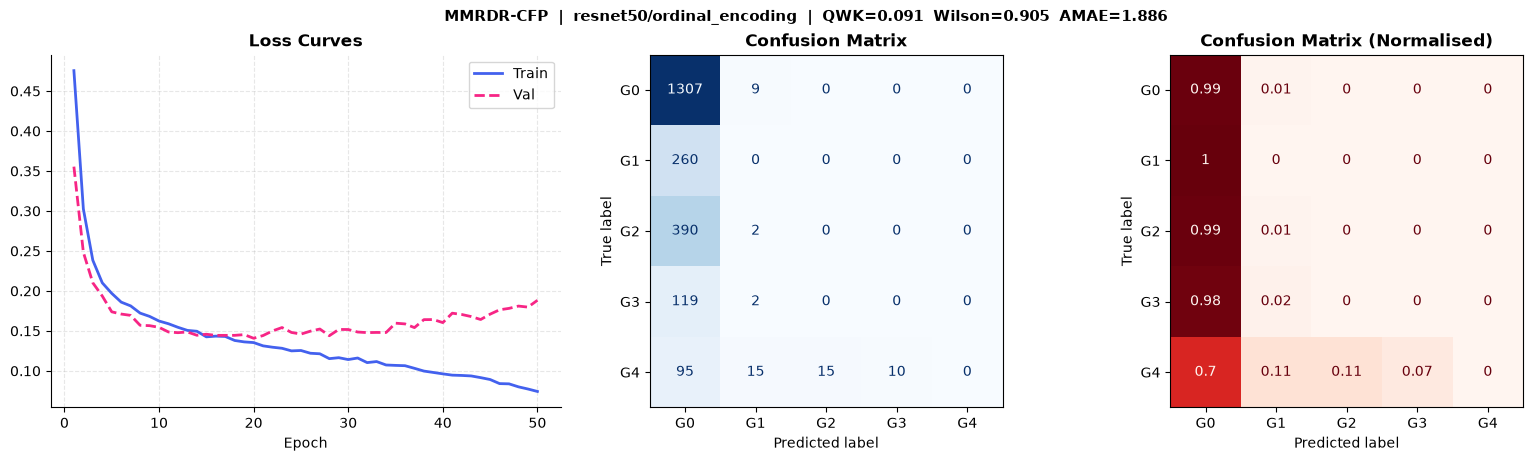

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\MMRDR_resnet50_ordinal_encoding_seed42\fold_0\train\plots\eval_summary.pdf


In [22]:
GRADE_LABELS = ['G0\n(No DR)', 'G1\n(Mild)', 'G2\n(Mod)', 'G3\n(Sev)', 'G4\n(PDR)']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

# Loss curves
ax = axes[0]
ep = range(1, len(loss_history) + 1)
ax.plot(ep, loss_history,     color='#4361EE', linewidth=2, label='Train')
ax.plot(ep, val_loss_history, color='#F72585', linewidth=2, label='Val', linestyle='--')
ax.set_xlabel('Epoch'); ax.set_title('Loss Curves', fontweight='bold')
ax.legend(); ax.spines[['top','right']].set_visible(False)
ax.grid(alpha=0.3, linestyle='--')

# Confusion matrix — counts
cm = confusion_matrix(y_true, y_pred)
labels_present = sorted(set(y_true.tolist() + y_pred.tolist()))
ConfusionMatrixDisplay(
    cm,
    display_labels=[GRADE_LABELS[i][:2] for i in labels_present]
).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title(f'Confusion Matrix', fontweight='bold')

# Confusion matrix — normalised
cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-9)
ConfusionMatrixDisplay(
    np.round(cm_norm, 2),
    display_labels=[GRADE_LABELS[i][:2] for i in labels_present]
).plot(ax=axes[2], cmap='Reds', colorbar=False)
axes[2].set_title('Confusion Matrix (Normalised)', fontweight='bold')

fig.suptitle(
    f'MMRDR-CFP  |  {MODEL_NAME}/{LOSS_NAME}  |  '
    f'QWK={kappa:.3f}  Wilson={wilson:.3f}  AMAE={amae:.3f}',
    fontsize=11, fontweight='bold'
)
out = TRAIN_FOLDER / 'plots' / 'eval_summary.pdf'
plt.savefig(out, bbox_inches='tight', dpi=200)
plt.show()
print(f'Saved → {out}')

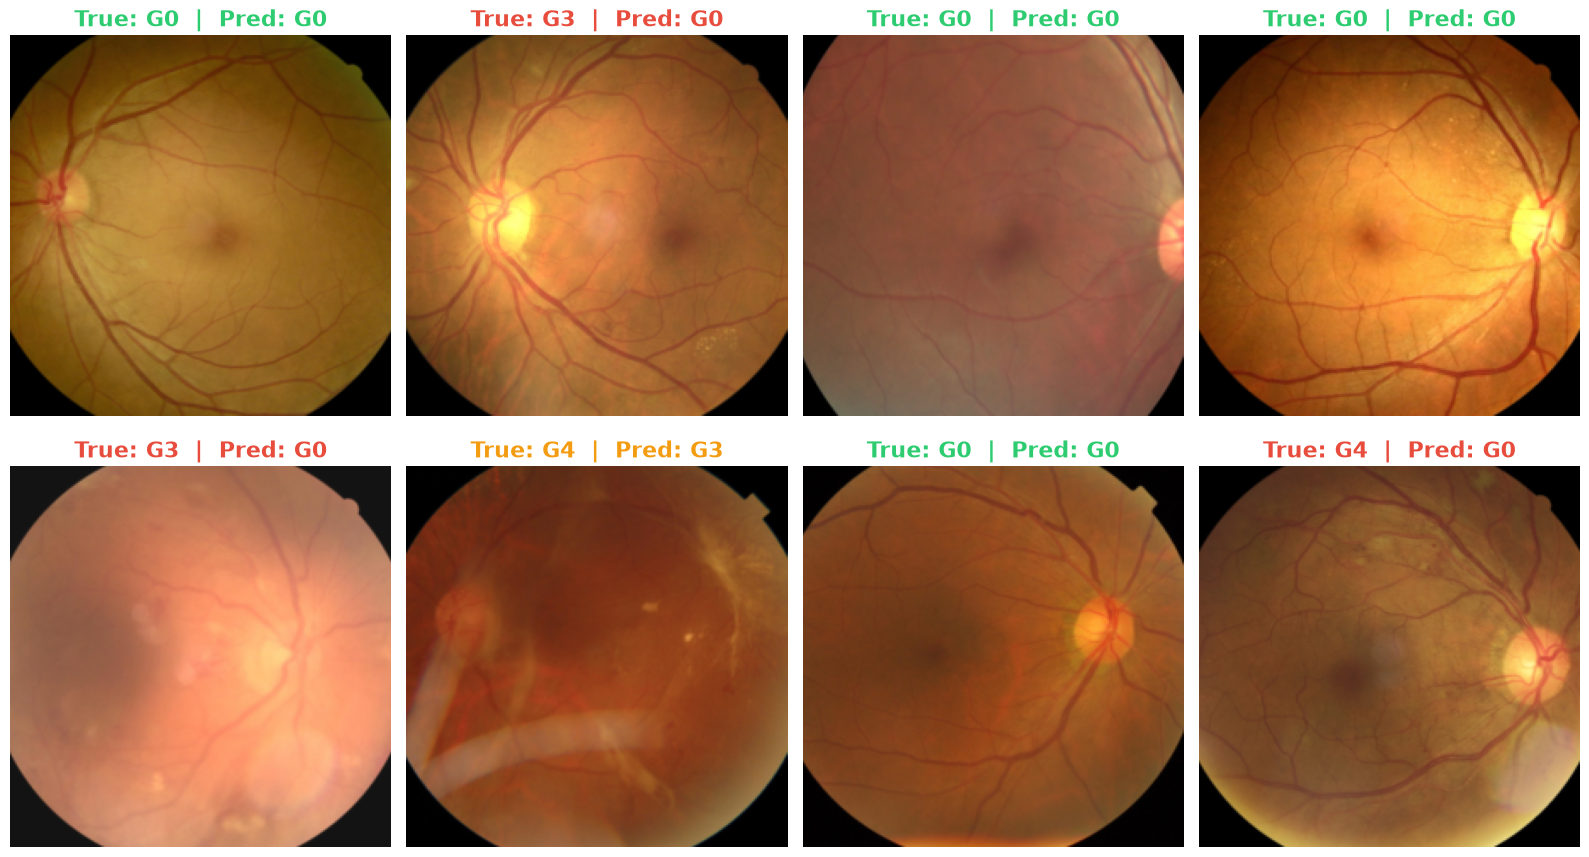

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure model is in eval mode
model.eval()

# 1. Grab one random batch from the validation set
images, labels = next(iter(val_loader))
images = images.to(DEVICE)

with torch.no_grad():
    outputs = model(images)
    preds = torch.argmax(outputs, dim=1)

# Move back to CPU for plotting
images = images.cpu()
labels = labels.cpu()
preds = preds.cpu()

# 2. Denormalize images (OrdinalDR uses standard ImageNet normalization)
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# 3. Plot a 2x4 grid
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.flatten()

for i in range(8):
    # Reverse the normalization and format for matplotlib
    img = images[i] * std + mean
    img = img.clamp(0, 1).permute(1, 2, 0).numpy()
    
    true_label = labels[i].item()
    pred_label = preds[i].item()
    
    # Ordinal Color Logic
    if true_label == pred_label:
        color = '#2ECC71'  # Green (Correct)
    elif abs(true_label - pred_label) == 1:
        color = '#F39C12'  # Orange (Off by 1)
    else:
        color = '#E74C3C'  # Red (Severe error, off by 2+)
        
    axes[i].imshow(img)
    axes[i].axis('off')
    
    # Set the title with the specific color
    axes[i].set_title(f'True: G{true_label}  |  Pred: G{pred_label}', 
                      color=color, fontweight='bold', fontsize=16)

plt.tight_layout()
plt.show()


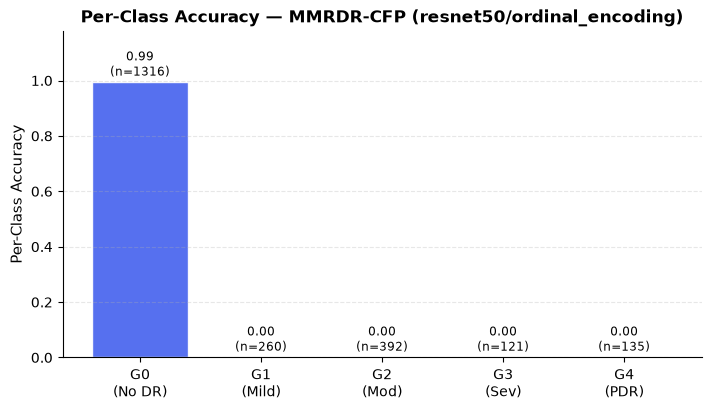

Saved → d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\MMRDR_resnet50_ordinal_encoding_seed42\fold_0\train\plots\per_class_accuracy.pdf


In [25]:
# Per-class accuracy
PALETTE = ['#4361EE','#7209B7','#F72585','#FF9E00','#06D6A0']
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
per_class_acc = cm.diagonal() / cm.sum(axis=1).clip(min=1)
class_counts  = cm.sum(axis=1)
x = np.arange(len(per_class_acc))
bars = ax.bar(x, per_class_acc,
              color=[PALETTE[i % len(PALETTE)] for i in x],
              edgecolor='white', alpha=0.9)
for bar, acc, n in zip(bars, per_class_acc, class_counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{acc:.2f}\n(n={int(n)})', ha='center', va='bottom', fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(GRADE_LABELS[:len(per_class_acc)], fontsize=10)
ax.set_ylabel('Per-Class Accuracy', fontsize=11)
ax.set_ylim(0, 1.18)
ax.set_title(f'Per-Class Accuracy — MMRDR-CFP ({MODEL_NAME}/{LOSS_NAME})', fontweight='bold')
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')
out2 = TRAIN_FOLDER / 'plots' / 'per_class_accuracy.pdf'
plt.savefig(out2, bbox_inches='tight', dpi=200)
plt.show()
print(f'Saved → {out2}')

## 8 · Checkpoint Summary

In [ ]:
print('='*60)
print(' CHECKPOINT SUMMARY')
print('='*60)
for label, path in [('Best model (inference)', BEST_CKPT), ('Full state  (resume)  ', LAST_CKPT)]:
    mb = path.stat().st_size / 1e6 if path.exists() else 0
    print(f'  {label}')
    print(f'    Path : {path}')
    print(f'    Size : {mb:.1f} MB')
    print()

if LAST_CKPT.exists():
    ckpt = torch.load(LAST_CKPT, map_location='cpu')
    print(f'  Last saved epoch  : {ckpt["epoch"]}')
    print(f'  Best Wilson index : {ckpt["best_wilson_idx"]:.4f}')
    print(f'  Epochs done       : {len(ckpt["loss_per_epoch"])} / {EPOCHS}')
    print()
    print('  To resume: re-run Cell 5 — checkpoint is detected automatically.')
print('='*60)

 CHECKPOINT SUMMARY
  Best model (inference)
    Path : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\resnet50_ce_seed42\fold_0\train\checkpoints\best_wilson.ckpt
    Size : 94.4 MB

  Full state  (resume)  
    Path : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\results\EXPERIMENTS\centralised\resnet50_ce_seed42\fold_0\train\checkpoints\last.ckpt
    Size : 282.6 MB

  Last saved epoch  : 49
  Best Wilson index : 0.4511
  Epochs done       : 50 / 50

  To resume: re-run Cell 5 — checkpoint is detected automatically.


## 9 . Rank Templates Similarity

Plots the cosine similarity between the learned class weights (rank templates).

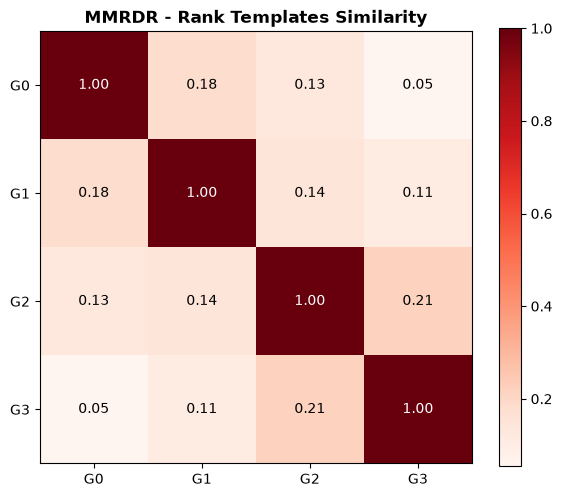

In [24]:
# Calculate and plot the similarity matrix of rank templates (final layer weights)
import torch.nn.functional as F

if hasattr(model, 'fc'):
    weights = model.fc.weight.detach()
elif hasattr(model, 'classifier') and isinstance(model.classifier, nn.Linear):
    weights = model.classifier.weight.detach()
elif hasattr(model, 'classifier') and isinstance(model.classifier[-1], nn.Linear):
    weights = model.classifier[-1].weight.detach()
else:
    weights = list(model.children())[-1].weight.detach()

# Cosine similarity matrix
normalized_weights = F.normalize(weights, p=2, dim=1)
sim_matrix = torch.mm(normalized_weights, normalized_weights.t()).cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(sim_matrix, cmap='Reds', interpolation='nearest', vmin=sim_matrix.min(), vmax=1.0)
fig.colorbar(cax)

num_classes = sim_matrix.shape[0]
ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels([f'G{i}' for i in range(num_classes)])
ax.set_yticklabels([f'G{i}' for i in range(num_classes)])
ax.set_title(f'{DATASET} - Rank Templates Similarity', fontweight='bold')

# Add text annotations
for i in range(num_classes):
    for j in range(num_classes):
        color = 'white' if sim_matrix[i, j] > (sim_matrix.max() + sim_matrix.min())/2 else 'black'
        ax.text(j, i, f'{sim_matrix[i, j]:.2f}', ha='center', va='center', color=color)

plt.tight_layout()
plt.savefig(TRAIN_FOLDER / 'plots' / 'template_similarity.png', dpi=120)
plt.show()
